<a href="https://colab.research.google.com/github/elvira123-hub/Lab/blob/main/students_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hartree-Fock method


## Import modules

In order to make work with the code easier one can use existing Python libraries. The most necessary ones are [NumPy](https://numpy.org/) and [SciPy](https://www.scipy.org/) for scientific programming and [Matplotlib](https://matplotlib.org/) for creating graphs and figures. More useful modules can be found on the [Python website](https://wiki.python.org/moin/UsefulModules).

In [ ]:
import numpy as np # used for matrix operations
import scipy # used for advanced mathematical functions
from scipy import special # will be needed for a few special functions
from copy import copy, deepcopy # needed for copying arrays and matrizes
import matplotlib.pyplot as plt # visualize results
import time # useful for tracking the calculation time
t_start = time.time() # get time at which the script starts

## Constants, parameters and basic data structures

It is good programming practice to define repeatedly needed constants and parameters in the beginning of the code. This makes it easier to find these values but also easier to change them as you just call a variable instead of writing numbers all the time - this way if you change something in the code you don't have to make sure to find all places where you used the number but instead just change the value of the respective constant first.

Initially some constants - values that will not be changed during the execution of the code - fill be defined. It is good practice to name these using only capital letters and in the unique way that tells not only you but also other people what the constant is used for. It makes the code a little longer but if find variables named 'ATOMIC_CHARGE' you will instantly know that they are used for. If they are named 'spam', 'aa' or 'ksdjbv' instead this will be much harder.

They will furthermore be defined as global variables to be used within all functions. Reason for this is that there are two different variable scopes in Python: the local and the global scope. The local scope are all variables created within functions -- outside their function they can't be accessed with not returned at the end of the function or stored otherwise. The global scope are variables that are avaiable everywhere within the code, also in functions -- this is especially useful for constants. But they need to be defined like this usingan additional statement.

### Basis function

In [ ]:
### Constants for basis function
global NR_GTO; NR_GTO = 3 # number of pGTO forming one cGTO in the STO-LG formalism
# contraction coefficients for STO-3G
global CONTRACTION; CONTRACTION = np.array([[0.444635, 0.535328, 0.154329],[0.444635, 0.535328, 0.154329]])
# exponents for STO-3G
global ALPHA;
#ALPHA = np.array([[0.480844, 1.776691, 9.753935], [0.168856, 0.623913, 3.42525]]) # HeH+
#ALPHA = np.array([[0.31364979, 1.15892300, 6.36242139], [0.168856, 0.623913, 3.42525]]) # HeH+ NWCHEM
ALPHA = np.array([[0.168856, 0.623913, 3.42525], [0.168856, 0.623913, 3.42525]]) # H2
global ZETA; ZETA = 1.24 # Slater orbital exponent

The basis set used is an single zeta STO-3G basis set which takes one contracted Gaussian-type orbital (cGTO) to approximate one Slater-type orbital (STO). The cGTO is constructed from 3 primitive Gaussian-type orbitals (pGTO). The equation for a single Gaussian function (GF) centered at $\vec{R_i}$ is
\begin{equation}
\phi^{\text{GF}}_{\text{1s}} (\alpha, \vec{r}-\vec{R_i})=\left( \frac{2\alpha}{\pi} \right)^\frac{3}{4}e^{-\alpha |\vec{r}-\vec{R_i}|^2}
\end{equation}
where $\alpha$ is the Gaussian orbital exponent. The resulting cGTO for hydrogen is then
\begin{equation}
\phi^{\text{CGF}}_{\text{1s}} = 0.444635 \phi^{\text{GF}}_{\text{1s}}(0.168856) + 0.535328 \phi^{\text{GF}}_{\text{1s}}(0.623913) + 0.154329 \phi^{\text{GF}}_{\text{1s}}(3.42525)
\end{equation}
to approximate a STO
\begin{equation}
\phi^{\text{SF}}_{\text{1s}} (\zeta, \vec{r}-\vec{R_i})=\left( \frac{\zeta^3}{\pi} \right)^\frac{1}{2}e^{-\zeta |\vec{r}-\vec{R_i}|}
\end{equation}
with $\zeta=1.24$ as the Slater orbital exponent. This is visualized in the following. To add further flexibility to the code, the basis set for atom 1 and atom 2 is defined individually.

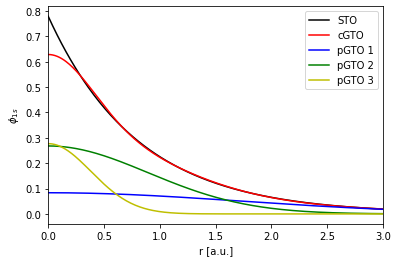

In [ ]:
x, SF, GF, CGF1, CGF2, CGF3 = [], [], [], [], [], [] # create arrays
# calculate values
for i in range(0, 301): # calculate values for interval from 0 a.u. to 3 a.u.
    r = i/100 # calculate radius in a.u.
    x.append(r) # x coordinate
    SF.append((ZETA**3/np.pi)**(0.5)*np.exp(-ZETA*r)) # Slater function
    CGF1.append(CONTRACTION[0,0]*((2*ALPHA[0,0])/np.pi)**(3/4)*np.exp(-ALPHA[0,0]*r**2)) # first pGTO
    CGF2.append(CONTRACTION[0][1]*((2*ALPHA[0][1])/np.pi)**(3/4)*np.exp(-ALPHA[0][1]*r**2)) # second pGTO
    CGF3.append(CONTRACTION[0][2]*((2*ALPHA[0][2])/np.pi)**(3/4)*np.exp(-ALPHA[0][2]*r**2)) # third pGTO
    GF.append(CGF1[i]+CGF2[i]+CGF3[i]) # cGTO
# plot functions
plt.figure("Orbital visualization") # initialize plot
plt.plot(x, SF, 'k-', label='STO') # show STO
plt.plot(x, GF, 'r-', label='cGTO') # show cGTO
plt.plot(x, CGF1, 'b-', label='pGTO 1') # show first pGTO
plt.plot(x, CGF2, 'g-', label='pGTO 2') # show second pGTO
plt.plot(x, CGF3, 'y-', label='pGTO 3') # show third pGTO
plt.xlabel('r [a.u.]') # label x axis
plt.ylabel(r'$\phi_{1s}$') # label y axis
plt.xlim(0.0, 3.0) # set x axis interval
plt.legend() # show legend
plt.show() # show plot

### Geometry

The hydrogen molecule is placed into the coordinate system in a way that the hydrogen atom A is located at the origin (0.0, 0.0, 0.0) and the hydrogen atom B at ($R$, 0.0, 0.0). This means that the molecule is placed along the x axis. Therefore the geometry can be simplified to a single variable: the bond length $R$. The nuclear charge of 1 is done using a constant as well to enable future extension to other systems.

In [ ]:
### Geometry
global NR_ATOMS; NR_ATOMS = 2 # total number of atoms
global RADIUS # bond length
#RADIUS = 1.4632 # bond length in a.u. for HeH+
RADIUS = 1.4 # bond length in a.u. for H2
global CHARGE # nuclear charge in a.u.
#CHARGE = [2, 1] # HeH+
CHARGE = [1, 1] # H2
# single atom energies
global E_ATOMS # energy of free atoms in a.u.
#E_ATOMS = [-2.643876, 0.0] # HeH+ -> He + H+
#E_ATOMS = [-1.975514, -0.466582] # HeH+ -> He+ + H
E_ATOMS = [-0.466582, -0.466582] # H2 -> H + H

### Code execution parameters

Some parameters for the execution of the code needs to be defined. In this code there will be only one: the treshold for the SCF procedure.

In [ ]:
### SCF parameters
global TRESHOLD; TRESHOLD = 0.000001 # treshold for change of density matrix between SCF steps

## Hartree-Fock method

This is the main function of the HF code. It will execute all other needed functions one after each other and will be called in the last lines of the code. This way the main algorithm of the method can be found at the beginning of the code and already use functions defined later. It also has general programming advantages, but these will not be utilized here.

The necessary steps to solve the Hartree-Fock equations will be described in the following:
1. Calculate the overlap matrix $S$ with matrix elements for the overlap of the cGTO using
\begin{equation}
S_{\mu\nu}=\int \text{d}\vec{r} \phi^{\text{CGF}}_{\mu}(\vec{r}-\vec{R_A}) \phi^{\text{CGF}}_{\nu}(\vec{r}-\vec{R_B}).
\end{equation}
2. Calculate the kinetic energy matrix $T$ with matrix elements
\begin{equation}
T_{\mu\nu}=\int \text{d}\vec{r} \phi^{\text{CGF}}_{\mu}(\vec{r}-\vec{R_A}) \left( -\frac{1}{2}\nabla^2 \right) \phi^{\text{CGF}}_{\nu}(\vec{r}-\vec{R_B}).
\end{equation}
3. Calculate the matrizes for the electron-core interactions $V_A$ and $V_B$ with matrix elements
\begin{equation}
V_{\mu\nu}=\int \text{d}\vec{r} \phi^{\text{CGF}}_{\mu}(\vec{r}-\vec{R_A}) \left( -\frac{Z_C}{|\vec{r}-\vec{R_C}|} \right) \phi^{\text{CGF}}_{\nu}(\vec{r}-\vec{R_B}).
\end{equation}
4. Calculate the core Hamiltonian $H^\text{core}$ from $T$, $V_A$ and $V_B$ using
\begin{equation}
H^\text{core}=T+V_A+V_B.
\end{equation}
5. Perform SCF procedure as described later.
6. Calculate energies as described later.

In [ ]:
def main():
    ### get matrizes
    S = Overlap() # obtain overlap matrix
    T = Kinetic() # obtain kinetic energy matrix
    V_A, V_B = Attraction() # obtain electron-core attraction matrizes
    H_core = T + V_A + V_B # obtain core Hamiltonian
    ### SCF procedure
    eig, C = SCF(S, H_core, True)
    ### calculate HF energy and total energy
    h11, J11 = 0.0, 0.0 # initialize matrix elements
    for a in range(0,2):
        for b in range(0,2):
            h11 += C[a,0]*C[b,0]*H_core[a,b]
            for c in range(0,2):
                for d in range(0,2):
                    J11 += C[a,0]*C[b,0]*C[c,0]*C[d,0]*Two(a,b,c,d)
    print('HF energies:')
    E_0 = 2*h11 + J11 # electronic energy
    print('E_0:', E_0)
    E_tot = E_0 + CHARGE[0]*CHARGE[1]/RADIUS # total energy
    print('E_tot:', E_tot)
    E_diss = E_tot - E_ATOMS[0] - E_ATOMS[1] # dissociation energy
    print('E_diss:', E_diss)


## Integral calculation

In the next section the integrals needed will be calculated. They will be calculated in the main() function. Please note that the good practice is to capitalize the first letter of a functions name to mark a function.

### Overlap integrals

The general overlap matrix element between the two cGTO $\phi^{\text{CGF}}_{\mu}$ and $\phi^{\text{CGF}}_{\nu}$ can be calculated as
\begin{equation}
S_{\mu\nu}=\int \text{d}\vec{r} \phi^{\text{CGF}}_{\mu}(\vec{r}-\vec{R_A}) \phi^{\text{CGF}}_{\nu}(\vec{r}-\vec{R_B}).
\end{equation}
Complex conjugation of the first function can be omitted as all basis functions are real. This can be expressed as a sum over the pGTO in the STO-LG basis set
\begin{equation}
S_{\mu\nu}= \sum_{i=1}^L \sum_{k=1}^L d_{i\mu} d_{k\nu} \int \text{d}\vec{r} \phi^{\text{GF}}_{i}(\alpha_{i\mu},\vec{r}-\vec{R_A}) \phi^{\text{GF}}_{k}(\alpha_{k\nu},\vec{r}-\vec{R_B})
\end{equation}
with the contraction coefficients $d_{i\mu}$ and $d_{k\nu}$. The integral is between two different pGTO functions and can be named as $S_{ik}$. As both pGTO are Gaussian functions
\begin{align}
\tilde{g}_\text{1s} (\alpha_{i\mu},\vec{r}-\vec{R_A}) &= e^{-\alpha_{i\mu} |\vec{r}-\vec{R_A}|^2}\\
\tilde{g}_\text{1s} (\alpha_{k\nu},\vec{r}-\vec{R_B}) &= e^{-\alpha_{k\nu} |\vec{r}-\vec{R_B}|^2}
\end{align}
their product is a Gaussian function as well so the integral
\begin{equation}
S_{ik} = \int \text{d}\vec{r} N \tilde{g}_\text{1s}(\alpha_{i\mu},\vec{r}-\vec{R_A}) \tilde{g}_\text{1s}(\alpha_{k\nu},\vec{r}-\vec{R_B})
\end{equation}
with the normalization factor
\begin{equation}
N=\left( \frac{2\alpha_{i\mu}}{\pi} \right)^\frac{3}{4} \left( \frac{2\alpha_{i\nu}}{\pi} \right)^\frac{3}{4}
\end{equation}
can be rewritten as
\begin{equation}
\tilde{g}_\text{1s} (\alpha,\vec{r}-\vec{R_A}) \tilde{g}_\text{1s} (\beta,\vec{r}-\vec{R_B})=\tilde{K}\tilde{g}_\text{1s} (p,\vec{r}-\vec{R_P})
\end{equation}
with
\begin{equation}
\tilde{K} = \exp \left( -\frac{\alpha\beta}{\alpha + \beta} |\vec{R_A}-\vec{R_B}|^2\right)
\end{equation}
and
\begin{equation}
\vec{R_P} = \frac{\alpha \vec{R_A} + \beta \vec{R_B}}{\alpha + \beta}
\end{equation}
where $\alpha_{i\mu}$ is renamed $\alpha$, $\alpha_{k\nu}$ is renamed $\beta$ and their sum $\alpha + \beta$ is called $p$. This way the overlap matrix element $S_{ik}$ can be easily calculated using
\begin{equation}
S_{ik} = N \tilde{K} \int \text{d}\vec{r_1} e^{-p |\vec{r_1}-\vec{R_p}|^2}.
\end{equation}
The substitutions $\vec{r}=\vec{r_1}-\vec{R_p}$ and $\text{d}\vec{r}=\text{d}\vec{r_1}$ result in the integral
\begin{equation}
S_{ik} = N \tilde{K} \int \text{d}\vec{r} e^{-p |\vec{r}|^2}.
\end{equation}
This can be solved using spherical coordinates which, after solving for the angular contributions, gives
\begin{equation}
S_{ik} = 4 \pi N \tilde{K} \int_0^\infty \text{d}r r^2 e^{-p r^2}.
\end{equation}
This integral can be solved analytically giving
\begin{equation}
S_{ik} = N \tilde{K} \left( \frac{\pi}{\alpha + \beta} \right)^{\frac{3}{2}}
\end{equation}
as the solution. This gives
\begin{equation}
S_{\mu\nu} = \sum_{i=1}^L \sum_{k=1}^L d_{i\mu} d_{k\nu} \left( \frac{2\alpha_{i\mu}}{\pi} \right)^\frac{3}{4} \left( \frac{2\alpha_{i\nu}}{\pi} \right)^\frac{3}{4} \exp \left( - \frac{\alpha_{i\mu}\alpha_{k\nu}}{\alpha_{i\mu}+\alpha_{k\nu}} | \vec{R_A} - \vec{R_B} |^2 \right) \left( \frac{\pi}{\alpha_{i\mu} + \alpha_{k\nu}} \right)^{\frac{3}{2}}
\end{equation}
as the final equation to calculate the overlap matrix elements. Now this can be implemented into the code using a function returning the complete overlap matrix $S$.

In [ ]:
def Overlap():
    S = np.zeros((NR_ATOMS, NR_ATOMS)) # overlap matrix initialization
    ### calculate integrals for all matrix elements
    for a in range(0, NR_ATOMS): # loop over all atoms - mu in equation
        for b in range(0, NR_ATOMS): # loop over all atoms - nu in equation
            integral = 0.0 # initialize variable to calculate sum over basis functions
            for i in range(0, NR_GTO): # loop over first pGTO - i in equation
                for k in range(0, NR_GTO): # loop over second pGTO - k in equation
                    # calculate first factor based only on basis functions, split into lines for readability
                    summand = CONTRACTION[a,i]*CONTRACTION[b,k]*(2*ALPHA[a,i]/np.pi)**(3/4)
                    summand *= (2*ALPHA[b,k]/np.pi)**(3/4)*(np.pi/(ALPHA[a,i]+ALPHA[b,k]))**(3/2)
                    # add second factor based also on considered atoms, evaluate absolute value depending on atom indices
                    summand *= np.exp(-(ALPHA[a,i]*ALPHA[b,k])/(ALPHA[a,i]+ALPHA[b,k])*(abs(a-b)*RADIUS)**2)
                    integral += summand # add to sum to evaluate integral after loops over basis functions
            S[a,b] = integral # set matrix element to calculated value
    S = S/S[0,0] # normalize overlap matrix
    return S # return statement, returns final overlap matrix
print('Overlap matrix S:\n', Overlap()) # console output resulting matrix

Overlap matrix S:
 [[1.         0.65931827]
 [0.65931827 1.        ]]


### Kinetic energy

The kinetic energy matrix elements $T_{\mu\nu}$ between two cGTO $\phi^{\text{CGF}}_{\mu}$ and $\phi^{\text{CGF}}_{\nu}$ are calculated similar to the overlap matrix elements using the kinetic energy operator $-\frac{1}{2}\nabla^2$. The general equation to calculate the matrix elements is
\begin{equation}
T_{\mu\nu}=\int \text{d}\vec{r} \phi^{\text{CGF}}_{\mu}(\vec{r}-\vec{R_A}) \left( -\frac{1}{2}\nabla^2 \right) \phi^{\text{CGF}}_{\nu}(\vec{r}-\vec{R_B}).
\end{equation}
After letting $\nabla^2$ operate one gets
\begin{equation}
T_{\mu\nu} = \sum_{i=1}^L \sum_{k=1}^L d_{i\mu} d_{k\nu} \left( \frac{2\alpha_{i\mu}}{\pi} \right)^\frac{3}{4} \left( \frac{2\alpha_{i\nu}}{\pi} \right)^\frac{3}{4} \left( \frac{\alpha_{i\mu}\alpha_{k\nu}}{\alpha_{i\mu}+\alpha_{k\nu}} \right) \left( \frac{\pi}{\alpha_{i\mu} + \alpha_{k\nu}} \right)^{\frac{3}{2}} \left( 3 - \frac{2\alpha_{i\mu}\alpha_{k\nu}}{\alpha_{i\mu}+\alpha_{k\nu}} | \vec{R_A} - \vec{R_B} |^2\right) \exp \left( - \frac{\alpha_{i\mu}\alpha_{k\nu}}{\alpha_{i\mu}+\alpha_{k\nu}} | \vec{R_A} - \vec{R_B} |^2 \right)
\end{equation}
as the equation to calculate the kinetic energy matrix elements. This can once again be implemented using a function returning the complete kinetic energy matrix $T$.

In [ ]:
def Kinetic():
    T = np.zeros((NR_ATOMS, NR_ATOMS)) # kinetic energy matrix initialization
    ### calculate integrals for all matrix elements
    for a in range(0, NR_ATOMS): # loop over all atoms - mu in equation
        for b in range(0, NR_ATOMS): # loop over all atoms - nu in equation
            integral = 0.0 # initialize variable to calculate sum over basis functions
            for i in range(0, NR_GTO): # loop over first pGTO - i in equation
                for k in range(0, NR_GTO): # loop over second pGTO - k in equation
                    # calculate first factor based only on basis functions, split into lines for readability
                    summand = CONTRACTION[a,i]*CONTRACTION[b,k]*(2*ALPHA[a,i]/np.pi)**(3/4)
                    summand *= (2*ALPHA[b,k]/np.pi)**(3/4)*(ALPHA[a,i]*ALPHA[b,k])/(ALPHA[a,i]+ALPHA[b,k])
                    summand *= (np.pi/(ALPHA[a,i]+ALPHA[b,k]))**(3/2)
                    # add second factor based containing distance depending terms
                    summand *= 3 - (2*ALPHA[a,i]*ALPHA[b,k])/(ALPHA[a,i]+ALPHA[b,k])*(abs(a-b)*RADIUS)**2
                    summand *= np.exp(-(ALPHA[a,i]*ALPHA[b,k])/(ALPHA[a,i]+ALPHA[b,k])*(abs(a-b)*RADIUS)**2)
                    integral += summand # add to sum to evaluate integral after loops over basis functions
            T[a,b] = integral # set matrix element to calculated value
    return T # return statement, returns final kinetic energy matrix
print('Kinetic energy matrix T:\n', Kinetic()) # console output resulting matrix

Kinetic energy matrix T:
 [[0.76003235 0.23645527]
 [0.23645527 0.76003235]]


### Electron-core attraction

The interaction between the electrons and the cores is treated using Coulomb interaction. The interaction of the electrons with the core of atom $C$ can thus be described as $-\frac{Z_C}{|\vec{r}-\vec{R_C}|}$ with $Z_C$ as the nuclear charge and $\vec{R_C}$ as the position of atom $C$. As there are two atoms in the system there will be two matrizes $V_A$ and $V_B$ for the interaction with atom $A$ and $B$. They are equivalent to each other except of an interchange of the indizes -- so the matrix only needs to be calculated once. This will be shows in the following for $V=V_A$, the attraction on the electrons towards core $C=A$.

The general matrix elements can be calculated from the integral
\begin{equation}
V_{\mu\nu}=\int \text{d}\vec{r} \phi^{\text{CGF}}_{\mu}(\vec{r}-\vec{R_A}) \left( -\frac{Z_C}{|\vec{r}-\vec{R_C}|} \right) \phi^{\text{CGF}}_{\nu}(\vec{r}-\vec{R_B}).
\end{equation}
Including the pGTO basis functions and combining the two Gaussians to a single Gaussian gives
\begin{equation}
V_{\mu\nu} =  N  \sum_{i=1}^L \sum_{k=1}^L d_{i\mu} d_{k\nu} \int \text{d} \vec{r} \tilde{K} e^{-p|\vec{r}-\vec{R_C}|^2} \left( -Z_C |\vec{r}-\vec{R_C}|^{-1} \right).
\end{equation}
As demonstrated in Appendix A in the book of Szabo and Ostlund (p.413 -- p.415) the integral $V_{ik}$ can be transformed using the Fourier integral theorem resulting in an expression
\begin{equation}
V_{ik} = - \frac{2\pi Z_C }{\alpha+\beta}\exp \left( -\frac{\alpha\beta}{\alpha+\beta} |\vec{R_A}-\vec{R_B}|^2 \right) F_0\left( (\alpha+\beta) |\vec{R_P}-\vec{R_C}|^2\right).
\end{equation}
The auxiliary function $F_0(t)$ is related to the error function $erf(x)$ by
\begin{equation}
F_0(t)=\frac{1}{2} \left( \frac{\pi}{t} \right)^\frac{1}{2} erf \left( \sqrt{t} \right).
\end{equation}
This gives the final equation for the calculation of the kinetic energy matrix elements
\begin{equation}
V_{\mu\nu} =  \sum_{i=1}^L \sum_{k=1}^L d_{i\mu} d_{k\nu} \left( \frac{2\alpha_{i\mu}}{\pi} \right)^\frac{3}{4} \left( \frac{2\alpha_{i\nu}}{\pi} \right)^\frac{3}{4} \left[ - \frac{2\pi Z_C }{\alpha+\beta}\exp \left( -\frac{\alpha\beta}{\alpha+\beta} |\vec{R_A}-\vec{R_B}|^2 \right) \right] F_0\left( (\alpha+\beta) |\vec{R_P}-\vec{R_C}|^2\right).
\end{equation}
For the specific geometry the result of $F_0(t)$ can be simplified depending on the cGTO which are integrated with. As $\vec{R_C}$ is treated as $\vec{R_A}$ here the expression can be further simplified as atom $A$ is placed in the origin. If the basis functions are located on different atoms $(\mu \neq \nu)$ one gets
\begin{equation}
|\vec{R_P}-\vec{R_A}|^2 = \left| \frac{\alpha \vec{R_A} + \beta \vec{R_B}}{\alpha + \beta} - \vec{R_A} \right| = \left|  \frac{\beta R}{\alpha + \beta}\right|
\end{equation}
because $\vec{R_A}=(0.0, 0.0, 0.0)$ and $\vec{R_B}=(R, 0.0, 0.0)$. If both basis functions are located at atom $B$ then $\vec{R_P}=\vec{R_B}$ and one obtains $|\vec{R_B}-\vec{R_A}|^2 = R$. The third case where both basis functions belong to atom $A$ becomes trickier as this involves finding the limit $\lim_{t \rightarrow 0} F_0(t)$ because $|\vec{R_A}-\vec{R_A}|^2 = 0$. Using the shorter notation $t = (\alpha+\beta) |\vec{R_P}-\vec{R_C}|^2 = p|r|^2$ finding the limit can be done as shown in the following using l'Hospital's rule:
\begin{align}
\lim_{r \rightarrow 0} F_0(p|r|^2) &= \frac{\sqrt{\pi}}{2} \lim_{r \rightarrow 0}  \left( \frac{1}{p|r|^2} \right)^\frac{1}{2} erf \left( \sqrt{p|r|^2} \right) \\
&= \frac{\sqrt{\pi}}{2\sqrt{p}} \lim_{r \rightarrow 0} \frac{erf \left( \sqrt{p|r|^2} \right)}{|r|}  \\
&= \frac{\sqrt{\pi}}{2\sqrt{p}} \lim_{r \rightarrow 0} \frac{\frac{\text{d}}{\text{d}r} erf \left( \sqrt{p|r|^2} \right)}{\frac{\text{d}}{\text{d}r} |r|} \\
&= \frac{\sqrt{\pi}}{2\sqrt{p}} \lim_{r \rightarrow 0} \frac{ 2\sqrt{p} e^{-p|r|^2} \frac{\text{d}}{\text{d}r} |r|}{ \sqrt{\pi} \frac{\text{d}}{\text{d}r} |r|} \\
&= \frac{\sqrt{\pi}}{2\sqrt{p}} \lim_{r \rightarrow 0} \frac{ 2\sqrt{p} e^{-p|r|^2}}{ \sqrt{\pi}} \\
&= \frac{\sqrt{\pi}}{2\sqrt{p}} \frac{ 2\sqrt{p}}{ \sqrt{\pi}}\\
&= 1.
\end{align}
Applying these results gives a function to calculate both electron-core attraction matrizes $V_A$ and $V_B$ using the symmetry within the molecule.

In [ ]:
def Attraction():
    V_A = np.zeros((NR_ATOMS, NR_ATOMS)) # electron-core interaction matrix for atom A initialized
    V_B = np.zeros((NR_ATOMS, NR_ATOMS)) # electron-core interaction matrix for atom B initialized
    ### calculate integrals for all matrix elements - V_A
    for a in range(0, NR_ATOMS): # loop over all atoms - mu in equation
        for b in range(0, NR_ATOMS): # loop over all atoms - nu in equation
            integral = 0.0 # initialize variable to calculate sum over basis functions
            for i in range(0, NR_GTO): # loop over first pGTO - i in equation
                for k in range(0, NR_GTO): # loop over second pGTO - k in equation
                    # calculate first factor based only on basis functions, split into lines for readability
                    summand = CONTRACTION[a,i]*CONTRACTION[b,k]*(2*ALPHA[a,i]/np.pi)**(3/4)*(2*ALPHA[b,k]/np.pi)**(3/4)
                    # add second factor based containing regular distance depending terms
                    summand *= - (2*np.pi)/(ALPHA[a,i]+ALPHA[b,k])
                    summand *= np.exp(-(ALPHA[a,i]*ALPHA[b,k])/(ALPHA[a,i]+ALPHA[b,k])*(abs(a-b)*RADIUS)**2)
                    # add third term depending on the atoms the basis functions belong to, calculated for atom A
                    if (a+b)!=0: # both basis functions located at atom A: F_0(t) is not needed (case three)
                        # calculate distance first, then F_0(t)
                        if a!=b and b>a: distance = abs(ALPHA[b,k]*RADIUS/(ALPHA[a,i]+ALPHA[b,k])) # use case one
                        elif a!=b and b<a: distance = abs(ALPHA[a,i]*RADIUS/(ALPHA[a,i]+ALPHA[b,k])) # use case one
                        elif a==b: distance = RADIUS # use case two
                        summand *= 0.5*(np.pi/((ALPHA[a,i]+ALPHA[b,k])*distance**2))**0.5
                        summand *= scipy.special.erf(((ALPHA[a,i]+ALPHA[b,k])*distance**2)**0.5)
                    integral += summand # add to sum to evaluate integral after loops over basis functions
            V_A[a,b] = integral*CHARGE[0] # set matrix element to calculated value
    ### calculate integrals for all matrix elements - V_B
    for a in range(0, NR_ATOMS): # loop over all atoms - mu in equation
        for b in range(0, NR_ATOMS): # loop over all atoms - nu in equation
            integral = 0.0 # initialize variable to calculate sum over basis functions
            for i in range(0, NR_GTO): # loop over first pGTO - i in equation
                for k in range(0, NR_GTO): # loop over second pGTO - k in equation
                    # calculate first factor based only on basis functions, split into lines for readability
                    summand = CONTRACTION[a,i]*CONTRACTION[b,k]*(2*ALPHA[a,i]/np.pi)**(3/4)*(2*ALPHA[b,k]/np.pi)**(3/4)
                    # add second factor based containing regular distance depending terms
                    summand *= - (2*np.pi)/(ALPHA[a,i]+ALPHA[b,k])
                    summand *= np.exp(-(ALPHA[a,i]*ALPHA[b,k])/(ALPHA[a,i]+ALPHA[b,k])*(abs(a-b)*RADIUS)**2)
                    # add third term depending on the atoms the basis functions belong to, calculated for atom A
                    if (a+b)!=2: # both basis functions located at atom A: F_0(t) is not needed (case three)
                        # calculate distance first, then F_0(t)
                        if a!=b and b<a: distance = abs(ALPHA[b,k]*RADIUS/(ALPHA[a,i]+ALPHA[b,k])) # use case one
                        elif a!=b and b>a: distance = abs(ALPHA[a,i]*RADIUS/(ALPHA[a,i]+ALPHA[b,k])) # use case one
                        elif a==b: distance = RADIUS # use case two
                        summand *= 0.5*(np.pi/((ALPHA[a,i]+ALPHA[b,k])*distance**2))**0.5
                        summand *= scipy.special.erf(((ALPHA[a,i]+ALPHA[b,k])*distance**2)**0.5)
                    integral += summand # add to sum to evaluate integral after loops over basis functions
            V_B[a,b] = integral*CHARGE[1] # set matrix element to calculated value
    return V_A, V_B # return statement, returns final matrizes
# console output to check values
V_A, V_B = Attraction() # get values for console output
print('Electron-core interaction matrix V_A:'+'\n', V_A)
print('Electron-core interaction matrix V_B:'+'\n', V_B)

Electron-core interaction matrix V_A:
 [[-1.22661494 -0.59741825]
 [-0.59741825 -0.65382809]]
Electron-core interaction matrix V_B:
 [[-0.65382809 -0.59741825]
 [-0.59741825 -1.22661494]]


### Two-electron integrals

Up to now all integrals involved only one electron to calculate overlap, kinetic energy and the electron-core interactions. To also include the electron-electron interaction in the equations, one needs to also include two-electron integrals. The corresponding integrals $(\mu\nu|\lambda \sigma)$ incolve 4 basis functions which can be located at atom $A$ or $B$ respectively. Formally, this results in 16 different integrals. Using commutation relations
\begin{equation}
(\mu\nu|\lambda \sigma) = (\mu\nu|\sigma \lambda) = (\lambda \sigma|\mu\nu)
\end{equation}
this can be simplified giving only four unique integrals. These one-center integrals
\begin{equation}
(\phi_A \phi_A|\phi_A \phi_A) = (\phi_B \phi_B|\phi_B \phi_B)
\end{equation}
as well as two-center integrals
\begin{equation}
(\phi_A \phi_A|\phi_B \phi_B)=(\phi_B \phi_B|\phi_A \phi_A).
\end{equation}
Furthermore integrals without a classical interpretation can be found:
\begin{equation}
(\phi_A \phi_A|\phi_A \phi_B) = (\phi_A \phi_A|\phi_B \phi_A) = (\phi_A \phi_B|\phi_A \phi_A) = (\phi_B \phi_A|\phi_A \phi_A) = (\phi_B \phi_B|\phi_B \phi_A) = (\phi_B \phi_B|\phi_A \phi_B) = (\phi_B \phi_A|\phi_B \phi_B) = (\phi_A \phi_B|\phi_B \phi_B)
\end{equation}
\begin{equation}
(\phi_A \phi_B|\phi_B \phi_A) = (\phi_A \phi_B|\phi_A \phi_B) = (\phi_B \phi_A|\phi_A \phi_B) = (\phi_B \phi_A|\phi_B \phi_A).
\end{equation}
To calculate these integrals the expression
\begin{equation}
(\phi_A \phi_B|\phi_C \phi_D) = \int \int \text{d}\vec{r_1} \text{d} \vec{r_2} \tilde{g}_\text{1s}(\alpha, \vec{r_1}-\vec{R_A}) \tilde{g}_\text{1s}(\beta, \vec{r_1}-\vec{R_B}) \frac{1}{r_{12}} \tilde{g}_\text{1s}(\gamma, \vec{r_2}-\vec{R_C}) \tilde{g}_\text{1s}(\delta, \vec{r_2}-\vec{R_D})
\end{equation}
with four general centers $A$, $B$, $C$ and $D$ needs to be evaluated. The operator $\frac{1}{r_{12}}$ describes the Coulomb interaction between the two electrons at $\vec{r_1}$ and $\vec{r_2}$. Once again the gaussian functions $\phi_A$ and $\phi_B$ as well as $\phi_C$ and $\phi_D$ can be combined to a new Gaussian. This gives
\begin{equation}
(\phi_A \phi_B|\phi_C \phi_D) =\exp \left( -\frac{\alpha \beta}{\alpha+\beta} |\vec{R_A}-\vec{R_B}|^2 - \frac{\gamma \delta}{\gamma + \delta} |\vec{R_C}-\vec{R_D}|^2 \right) \int \int \text{d}\vec{r_1} \text{d} \vec{r_2} e^{-p|\vec{r_1}-\vec{R_P}|} \frac{1}{r_{12}} e^{-q|\vec{r_2}-\vec{R_Q}|}
\end{equation}
with $p=\alpha+\beta$, $\vec{R_P}=\frac{\alpha \vec{R_A} + \beta \vec{R_B}}{\alpha + \beta}$, $q=\gamma+\delta$ and $\vec{R_Q}=\frac{\gamma \vec{R_C} + \delta \vec{R_D}}{\gamma + \delta}$. Using Fourier transformed integration similar to the electron-core interaction using the auxiliary function $F_0(t)$ the integral can be transformed to
\begin{equation}
(\phi_A \phi_B|\phi_C \phi_D) = \frac{2\pi^\frac{5}{2}}{(\alpha+\beta)(\gamma+\delta)(\alpha+\beta+\gamma+\delta)^\frac{1}{2}} \exp \left( -\frac{\alpha \beta}{\alpha+\beta} |\vec{R_A}-\vec{R_B}|^2 - \frac{\gamma \delta}{\gamma + \delta} |\vec{R_C}-\vec{R_D}|^2 \right) F_0\left( \frac{(\alpha+\beta)(\gamma+\delta)}{\alpha+\beta+\gamma+\delta}  |\vec{R_P}-\vec{R_Q}|^2 \right).
\end{equation}
As this currently only includes pGTO $\phi$, the final expression for the cGTO $\psi$ is
\begin{equation}
(\psi_A \psi_B|\psi_C \psi_D) = \sum_{k=1}^L \sum_{l=1}^L \sum_{m=1}^L \sum_{n=1}^L d_{kA} d_{lB} d_{mC} d_{nD}
\left( \frac{2\alpha_{kA}}{\pi} \right)^\frac{3}{4} \left( \frac{2\alpha_{lB}}{\pi} \right)^\frac{3}{4} \left( \frac{2\alpha_{mC}}{\pi} \right)^\frac{3}{4} \left( \frac{2\alpha_{nD}}{\pi} \right)^\frac{3}{4} (\phi_A \phi_B|\phi_C \phi_D)
\end{equation}
with $\alpha_{kA}=\alpha$, $\alpha_{lB}=\beta$, $\alpha_{mC}=\gamma$ and $\alpha_{nD}=\delta$. The function to calculate these values will be implemented in a different way compared to the matrizes before: the indizes of $(\psi_A \psi_B|\psi_C \psi_D)$ will be given to the function as arguments using $0$ for atom $A$ and $1$ for atom $B$. The function will then be called 4 times to calculate the 4 individual two-electron integrals.

In [ ]:
def Two(A,B,C,D):
    integral = 0.0 # initialize variable to calculate sum over basis functions
    for k in range(0, NR_GTO): # loop over first pGTO - k in equation
        for l in range(0, NR_GTO): # loop over second pGTO - l in equation
            for m in range(0, NR_GTO): # loop over third pGTO - m in equation
                for n in range(0, NR_GTO): # loop over fourth pGTO - n in equation
                    # first step: contraction coefficients and normalization constants
                    summand = CONTRACTION[A,k]*CONTRACTION[B,l]*CONTRACTION[C,m]*CONTRACTION[D,n]
                    summand *= (2*ALPHA[A,k]/np.pi)**(3/4)*(2*ALPHA[B,l]/np.pi)**(3/4)
                    summand *= (2*ALPHA[C,m]/np.pi)**(3/4)*(2*ALPHA[D,n]/np.pi)**(3/4)
                    # second step: factor based on regular distance dependent terms
                    summand *= (2*np.pi**(5/2))/((ALPHA[A,k]+ALPHA[B,l])*(ALPHA[C,m]+ALPHA[D,n]))
                    summand *= 1/((ALPHA[A,k]+ALPHA[B,l]+ALPHA[C,m]+ALPHA[D,n])**(1/2))
                    summand *= np.exp(-ALPHA[A,k]*ALPHA[B,l]/(ALPHA[A,k]+ALPHA[B,l])*abs(A-B)*RADIUS**2)
                    summand *= np.exp(-ALPHA[C,m]*ALPHA[D,n]/(ALPHA[C,m]+ALPHA[D,n])*abs(C-D)*RADIUS**2)
                    # third step: factor based on auxiliary function F_0(t)
                    R_P = (ALPHA[A,k]*A*RADIUS+ALPHA[B,l]*B*RADIUS)/(ALPHA[A,k]+ALPHA[B,l])
                    R_Q = (ALPHA[C,m]*C*RADIUS+ALPHA[D,n]*D*RADIUS)/(ALPHA[C,m]+ALPHA[D,n])
                    t = (ALPHA[A,k]+ALPHA[B,l])*(ALPHA[C,m]+ALPHA[D,n])/(ALPHA[A,k]+ALPHA[B,l]+ALPHA[C,m]+ALPHA[D,n])
                    t *= abs(R_P - R_Q)**2
                    if t!=0: # avoid problem with limits
                        summand *= 0.5*(np.pi/t)**(1/2)*scipy.special.erf(t**(1/2))
                    integral += summand # add so sum over basis functions
    return integral # return statement, returns final value
# console output to check values
print('(AA|AA):', Two(0,0,0,0))
print('(AA|BB):', Two(0,0,1,1))
print('(AA|AB):', Two(0,0,0,1))
print('(AB|AB):', Two(0,1,0,1))
print('Additionally for HeH+:')
print('(BB|BA):', Two(1,1,1,0))
print('(BB|BB):', Two(1,1,1,1))

(AA|AA): 0.7746079055149163
(AA|BB): 0.5696774985883127
(AA|AB): 0.44410895821292995
(AB|AB): 0.29702949599279344
Additionally for HeH+:
(BB|BA): 0.44410895821292995
(BB|BB): 0.7746079055149163


## Solving the Roothaan-Hall equations

### The Hartree-Fock energy

In this code a closed-shell Hartree-Fock method -- called Restricted Hartree-Fock (RHF) -- will be used. This means that the same spatial function is used for electrons with spin up and spin down and that every orbital is fully occupied by two paired electrons thus having a closed shell. This is used to eliminate the explizit inclusion of the electron spin in the equations. From this the closed-shell Hartree-Fock energy can be obtained by
\begin{equation}
E_0 = 2 \sum_i h_{ii} + \sum_i \sum_j \left( 2 J_{ij}+K_{ij} \right)
\end{equation}
using the core hamiltonian matrix elements $h_{ii}$ and the Coulomb and exchange integrals $J_{ij}$ and $K_{ij}$.
The single orbital energy $\epsilon_i$ of orbital $i$ is obtained from
\begin{equation}
\epsilon_i = h_{ii} + \sum_j^{\frac{N}{2}} \left( 2J_{ij}+K_{ij} \right).
\end{equation}
The total energy $E_\text{tot}$ of a given system is calculated using the electronic energy $E_0$ and the core-core Coulomb interaction
\begin{equation}
E_\text{tot} = E_0 + \sum_A \sum_{B>A} \frac{Z_A Z_B}{R_{AB}}.
\end{equation}
For the given system the total energy can thus be calculated -- using that there is no exchange interaction between electron of antiparallel spin -- from
\begin{align}
E_\text{tot} &= E_0 + \frac{1}{R} \\
E_0 &= 2h_{11} + J_{11}.
\end{align}

### The Roothaan equations

Within the LCAO approximation the molecular orbitals (MO) of a system $\Psi$ can be expressed by linear combination of atomic orbitals (AO) $\psi$
\begin{equation}
\Psi_i = \sum_{\mu=1}^{K} C_{\mu i} \psi_\mu \text{  with } i=1,2,\cdots , K.
\end{equation}
This reduces the calculation of the MO to the calculation of the expansion coefficients $C_{\mu i}$. Including this in the Hartree-Fock equations gives
\begin{equation}
f(\vec{r_1}) \sum_\mu C_{\mu i} \psi_\mu (\vec{r_1}) = \epsilon_i \sum_\mu C_{\mu i} \psi_\mu (\vec{r_1}).
\end{equation}
The matrix equation
\begin{equation}
\sum_\mu C_{\mu i} \int \text{d} \vec{r_1} \psi_\nu^* (\vec{r_1}) f(\vec{r_1})   \psi_\mu (\vec{r_1}) = \epsilon_i \sum_\mu C_{\mu i} \int \text{d} \vec{r_1} \psi_\nu^* (\vec{r_1}) \psi_\mu (\vec{r_1})
\end{equation}
can be obtained by multiplication with $\psi_\nu^* (\vec{r_1})$ from the left. In this equation two matrizes can be defined: the overlap matrix $S$ with the matrix elements
\begin{equation}
S_{\nu \mu} =  \int \text{d} \vec{r_1} \psi_\nu^* (\vec{r_1}) \psi_\mu (\vec{r_1})
\end{equation}
and the Fock matrix $F$ with the matrix elements
\begin{equation}
F_{\nu \mu} = \int \text{d} \vec{r_1} \psi_\nu^* (\vec{r_1}) \psi_\mu (\vec{r_1}).
\end{equation}
The overlap matrix is positive-definite $K\times K$ matrix, Hermitian and can be diagonalized by a unitary matrix as used later. The Fock matrix is also a Hermitian $K\times K$ matrix and includes the one-electron operators. Using these definitions the matrix equation can be rewritten as
\begin{equation}
\sum_\mu F_{\nu \mu} C_{\mu i}  = \epsilon_i \sum_\mu S_{\nu \mu} C_{\mu i} \text{  with }i=1,2,\cdots,K.
\end{equation}
This is named the Roothaan equations and can be written in a single matrix equation
\begin{equation}
FC=SC\epsilon.
\end{equation}
Here $C$ is a $K\times K$ matrix of the expansion coefficients $C_{\mu i}$
\begin{equation}
C=\left( \begin{array}{rrr}C_{11} & \cdots & C_{1K}\\ \vdots & \ddots & \vdots \\C_{K1} & \cdots & C_{KK} \\ \end{array}\right)
\end{equation}
and $\epsilon$ is a diagonal matrix of the orbital energies $\epsilon_i$
\begin{equation}
\epsilon=\left( \begin{array}{rrr}\epsilon_i & \cdots & 0\\ \vdots & \ddots & \vdots \\0 & \cdots & \epsilon_K \\ \end{array}\right) .
\end{equation}
In matrix $C$ the columns describe the MOs, the lines the contribution of the AOs.

### Orthogonalization of the basis

The basis set used is not orthonormal, only the basis functions themself are normalized but not orthogonal to each other. To obtain Roothaan's equation in the usual matrix eigenvalue form, the basis functions needs to be orthogonalized first.

Currently the basis functions are not orthogonal as an overlap matrix $S$ is obtained with $0 \leq |S_{\nu \mu}| 1$. To find an orthogonal set in which the overlap is given by $\delta_{\nu \mu}$ a transformation matrix $X$ is needed. Using the Hermitian overlap matrix $S$ a diagonal matrix $s$ of the eigenvalues of $S$ can be obtained using a unitary matrix $U$
\begin{equation}
U^\dagger SU=s.
\end{equation}
The transformation matrix can be obtained using a so-called symmetric orthogonalization
\begin{equation}
X \equiv S^{-\frac{1}{2}} = U s^{-\frac{1}{2}} U^\dagger.
\end{equation}
Matrix $s$ can be constructed from the eigenvalues of $S$. When taking the inverse square root of each eigenvalues the matrix $s^{-\frac{1}{2}}$ is formed. The unitary matrix $U$ is constructed from the orthonormal basis of eigenvectors (columnwise) with respect to the eigenvalues. The adjoint (or conjugate transpose, German: adjungiert) matrix $U^\dagger$ is then obtained from $U$ by taking the transpose and then taking the complex conjugate of each entry. Using the now calculated transformation matrix the Roothaan equation can be reformulated. An alternative is the usage of orthogonalized basis function, but this would result in a time consuming recalculation of all four-electron integrals.

A new coefficient matrix $C'$ can be obtained from the old matrix $C$ by
\begin{equation}
C'=X^{-1}C,\ C=XC'.
\end{equation}
Substituting this into Roohaan's equations gives
\begin{equation}
FXC'=SXC'\epsilon.
\end{equation}
Multiplication with $X^\dagger$ from the left then gives
\begin{equation}
(X^\dagger FX)C'=(X^\dagger SX)C'\epsilon.
\end{equation}
The term $X^\dagger SX$ equals 1. Furthermore a new matrix $F'=X^\dagger FX$ is defined. This then gives the transformed Roothaan equations
\begin{equation}
F'C'=C'\epsilon.
\end{equation}
They will later be solved for $C'$ by diagonalizing $F'$ and then calculating $C$.

The Fock matrix itself is the matrix representation of the single particle Fock operator
\begin{equation}
f(\vec{r_1})=h(\vec{r_1})+\sum_j^{\frac{N}{2}} \left( 2J_j(\vec{r_1}) - K_j(\vec{r_1}) \right).
\end{equation}
Using the already calculated matrix elements one can calculate the Fock matrix elements by
\begin{align}
F_{\nu \mu} &= H_{\nu \mu}^\text{core} + \sum_j^{\frac{N}{2}} \sum_{\lambda \sigma} C_{\lambda j} C^*_{\sigma j} \left[ 2(\nu \mu | \sigma \lambda) - (\nu \lambda | \sigma \mu) \right] \\
&=   H_{\nu \mu}^\text{core} + \sum_{\lambda \sigma} P_{\lambda \sigma} \left[ (\nu \mu | \sigma \lambda) - \frac{1}{2}(\nu \lambda | \sigma \mu) \right] \\
&= H_{\nu \mu}^\text{core} + G_{\nu \mu}.
\end{align}
The term $P_{\lambda \sigma}$ is called density matrix. This term is obtained from the electron density $\rho (\vec{r})$ which is expanded within LCAO approximation. It is calculated from the expansion coefficients by
\begin{equation}
P_{\nu \mu} = 2 \sum_j^{\frac{N}{2}} C_{\nu j} C_{\mu j}^*.
\end{equation}

### The SCF procedure

To finally get the solution of the equations within the neccessary approximations the matrix equation needs to be solved using a SCF (self-consistent field) procedure because of the non-linearity of the problem. It is an iterative way to solve the eigenvalue problem in which the solution steps are repeated until convergence -- a constant energy value -- is reached. The necessary steps to perform the SCf procedure will be shown in the following:

1. Calculation of the transformation matrix X
\begin{equation}
X=U s^{-\frac{1}{2}} U^\dagger.
\end{equation}
2. Obtain an initial density matrix $P$ from guessed initial expansion coefficients
\begin{equation}
P_{\nu \mu} = 2 \sum_j^{\frac{N}{2}} C_{\nu j} C_{\mu j}^*.
\end{equation}
3. Calculate auxiliary matrix $G$
\begin{equation}
G_{\nu \mu} = \sum_{\lambda \sigma} P_{\lambda \sigma} \left[ (\nu \mu | \sigma \lambda) - \frac{1}{2}(\nu \lambda | \sigma \mu) \right].
\end{equation}
4. Calculate Fock matrix $F$
\begin{equation}
F_{\nu \mu} = H_{\nu \mu}^\text{core} + G_{\nu \mu}.
\end{equation}
5. Calculate transformed Fock matrix $F'$
\begin{equation}
F'=X^\dagger F X.
\end{equation}
6. Diagonalize $F'$ to obtain $C'$ and $\epsilon$
\begin{equation}
F'C'=C'\epsilon.
\end{equation}
7. Calculate $C$
\begin{equation}
C=XC'.
\end{equation}
8. Calculate new density matrix $P$ with new $C$
\begin{equation}
P_{\nu \mu} = 2 \sum_j^{\frac{N}{2}} C_{\nu j} C_{\mu j}^*.
\end{equation}
9. Check for convergence: A treshold of $\delta = 10^{-6} \text{ Hartree}$ will be used which equals $\delta = 10^{-4}$ for the error in the density matrix. If convergence is reached: proceed with step number 10. If no convergence is reached: do back to step number 3.
10. Calculate expectation values and other quantities from solution.

In [ ]:
def SCF(S, H, output):
    '''variable definition:
    S: initial overlap matrix
    H: core Hamiltonian matrix
    output : control whether console output will be written during SCF or not
    '''
    ### step 1: transformation matrix
    eig, U = np.linalg.eigh(S) # diagonalize S, get eigenvalues 'eig' and matrix of eigenvectors 'U'
    Uadj = np.matrix.transpose(U) # get adjoint matrix 'Uadj' assuming only real matrix elements
    s_sqrt = np.matrix([[eig[0]**(-1/2), 0.0], [0.0, eig[1]**(-1/2)]]) # negative sqrt matrix of eigenvalues
    X = U*s_sqrt*Uadj # calculate transformation matrix X
    Xadj = np.matrix.transpose(X) # get adjoint matrix 'Xadj' assuming only real matrix elements

    ### step 2: guess initial density matrix
    C = np.matrix([[1.0, 1.0], [1.0, -1.0]]) # "random" initial guess of coefficient matrix
    #S = Overlap()
    #C = np.matrix([[(2*(1+S[0,1]))**(-0.5), (2*(1-S[0,1]))**(-0.5)], [(2*(1+S[0,1]))**(-0.5), -(2*(1-S[0,1]))**(-0.5)]])
    if output: print("Initial guess AO coeff.:\n" + str(C)) # console output
    P = np.matrix([[2*C[0,0]*C[0,0], 2*C[1,0]*C[0,0]], [2*C[0,0]*C[1,0], 2*C[1,0]*C[1,0]]]) # calculate density matrix
    if output: print("Initial density matrix:\n" + str(P) + '\n') # console output

    ### SCF routine
    step, delta = 1, 1E8 # variable to track the number of neccessary steps, initial value for delta
    if output: print('Starting SCF procedure!\n') # console output
    while delta > TRESHOLD: # SCF loop finished then converged
        if output: print('Step ' + str(step) + ':\n') # console output
        # step 3: calculate matrix G
        G = np.matrix([[0.0, 0.0],[0.0, 0.0]]) # initialize matrix G
        for a in range(0,2): # loop over first index in matrix elements
            for b in range(0,2): # loop over second index in matrix elements
                for c in range(0,2): # loop over first index in sum
                    for d in range(0,2): # loop over second index in sum
                        G[a,b] += P[c,d]*(Two(a,b,d,c) - 0.5*Two(a,c,d,b)) # add to matrix element
        # step 4: calculate Fock matrix F
        F = H + G
        # step 5: calculate transformed Fock matrix
        Ftrans = Xadj*F*X
        # step 6: diagonalize Ftrans to get Ctrans and new eigenvalues
        eig, Ctrans = np.linalg.eigh(Ftrans) # use this function to get eigenvalues sorted in ascending order
        # additional step: set convention to have first element of each eigenvector with positive sign
        sign1 = (abs(Ctrans[0,0])/Ctrans[0,0])
        sign2 = (abs(Ctrans[0,1])/Ctrans[0,1])
        Ctrans[0,0] = Ctrans[0,0] / sign1
        Ctrans[1,0] = Ctrans[1,0] / sign1
        Ctrans[0,1] = Ctrans[0,1] / sign2
        Ctrans[1,1] = Ctrans[1,1] / sign2
        C = X*Ctrans
        if output: print("New AO coeff.:\n" + str(C)) # console output
        # step 8: calculate new density matrix P
        P_new = np.matrix([[2*C[0,0]*C[0,0], 2*C[1,0]*C[0,0]],[2*C[0,0]*C[1,0], 2*C[1,0]*C[1,0]]])
        if output: print("New density matrix:\n" + str(P_new) + '\n') # console output
        # step 9: check convergence
        delta = 0.0 # (re-)initialize difference delta
        for i in range(0,2):
            for j in range(0,2):
                delta += (P[i,j] - P_new[i,j])**2 # squared difference
        delta = np.sqrt(delta) # get difference
        P = deepcopy(P_new) # set new density matrix to regular density matrix for next step
        step += 1 # go on to next step
    if output: print('\nSCF procedure converged!\nSteps taken: ' + str(step-1) + '\n')
    return eig, C # return statement

## Results

### Hartree-Fock and dissociation energy

In [ ]:
#=====#
# Run #
#=====#

if __name__ == '__main__':
    main()

Initial guess AO coeff.:
[[ 1.  1.]
 [ 1. -1.]]
Initial density matrix:
[[2. 2.]
 [2. 2.]]

Starting SCF procedure!

Step 1:

New AO coeff.:
[[ 0.54893403  1.21146419]
 [ 0.54893403 -1.21146419]]
New density matrix:
[[0.60265714 0.60265714]
 [0.60265714 0.60265714]]

Step 2:

New AO coeff.:
[[ 0.54893403  1.21146419]
 [ 0.54893403 -1.21146419]]
New density matrix:
[[0.60265714 0.60265714]
 [0.60265714 0.60265714]]


SCF procedure converged!
Steps taken: 2

HF energies:
E_0: -1.8310015845863183
E_tot: -1.1167158703006042
E_diss: -0.1835518703006041


# Configuration interaction

In the Hartree-Fock theory a single Slater determinant is used to describe the many-particle wave function. But this single-particle approximation gives an error. To fix this a series of Slater determinants for the gound state and excited states is used to improve the description of the correlation energy.

For a molecule with $N$ electrons  and $K$ basis functions, the HF theory gives $2K$ spin orbitals with $2K-N$ virtual orbitals. This gives a total number of
\begin{equation}
\left( \begin{array}{r} 2K \\ N \end{array} \right) = \frac{(2K)!}{N!(2K-N)!}
\end{equation}
possible Slater determinants for a given system. Starting from the ground state Slater determinant
\begin{equation}
|\Psi_0> = |\chi_1\chi_2 \cdots \chi_a \chi_b \cdots \chi_N>
\end{equation}
the single excitation Slater determinant for the excitation of an electron from orbital $a$ to $r$ can be written as
\begin{equation}
|\Psi_a^r> = |\chi_1\chi_2 \cdots \chi_r \chi_b \cdots \chi_N>
\end{equation}
and a double excitation Slater determinant as
\begin{equation}
|\Psi_{ab}^{rs}> = |\chi_1\chi_2 \cdots \chi_r \chi_s \cdots \chi_N>.
\end{equation}
For a given basis the full CI (FCI) wave function can be obtained from the ground and excited states as
\begin{equation}
|\Phi> = c_0|\Psi_0> + \sum_a \sum_r c_a^r |\Psi_a^r> + \sum_{a<b} \sum_{r<s} c_{ab}^{rs} |\Psi_{ab}^{rs}> + \sum_{a<b<c} \sum_{r<s<t} c_{abc}^{rst} |\Psi_{abc}^{rst}> + \cdots.
\end{equation}
In a complete basis this gives the exact non-relativistic limit of the energy. For an incomplete basis it gives the exact solution for the basis used - this can be improved by increasing the size of the basis set.

In the SZ hydrogen molecule, the FCI wave function is drastically simplified compared to larger systems. Only 6 unique Slater determinants exist:
* the ground state $|1\bar{1}>$,
* 4 single excited states $|2\bar{1}>$, $|\bar{2}\bar{1}>$, $|12>$, $|1\bar{2}>$ and
* the double excited state $|2\bar{2}>$.

The Brillouin theoreme states that all single excitations give a contribution of zero to the FCI wave function, so it can be written as
\begin{equation}
|\Phi_0> = |\Psi_0> + c_\text{D} |\Psi_{1\bar{1}}^{2\bar{2}}>
\end{equation}
with $c_0=1$ (intermediate normalization, see p. 237ff) and $c_\text{D}$ being the ground state and double excitation coefficient respectively. The FCI energy is then obtained as the lowest eigenvalue of the FCI matrix
\begin{equation}
H = \left( \begin{array}{rr}
<\Phi_0|\hat{H}|\Phi_0> & <\Phi_0|\hat{H}|\Psi_{1\bar{1}}^{2\bar{2}}> \\
<\Phi_{1\bar{1}}^{2\bar{2}}|\hat{H}|\Psi_0> & <\Phi_{1\bar{1}}^{2\bar{2}}|\hat{H}|\Psi_{1\bar{1}}^{2\bar{2}}>
\end{array} \right).
\end{equation}
The required matrix elements are calculated by
\begin{align}
<\Phi_0|\hat{H}|\Phi_0> &= E_0 = 2h_{11} + J_{11} \\
<\Phi_0|\hat{H}|\Psi_{1\bar{1}}^{2\bar{2}}> &= <1\bar{1}|2\bar{2}>=(12|12)=K_{12}=<\Phi_{1\bar{1}}^{2\bar{2}}|\hat{H}|\Psi_0>\\
<\Phi_{1\bar{1}}^{2\bar{2}}|\hat{H}|\Psi_{1\bar{1}}^{2\bar{2}}> &= 2h_{22} + J_{22}.
\end{align}
This will be implemented in the following. According to eq. (4.19a) the excitation coefficient $c_\text{D}$ can be calculated from
\begin{equation}
E_\text{corr} = c_\text{D}K_{12}
\end{equation}
using the correlation energy
\begin{equation}
E_\text{corr} = E_\text{CI} - E_0.
\end{equation}
This will be implemented together with the MP theory as they share some values neccessary for their calculation

# Møller–Plesset perturbation theory

Møller–Plesset perturbation theory uses a fluctuation potential to perform perturbation calculations. In zeroth order this method just gives the sum of orbital energies as the total energy, the first order equals the Hartree-Fock energy. In this course the second order MP2 will be applied to hydrogen.

MP2 includes single and higher excitations into the energy expression. Actually single excitations - again - don't contribute to the energy as can be shown using the Brillouin theoreme. The perturbation potential is a two-electron potential, thus only double excitation needs to be considered of all possible higher excitations as the higher excited Slater determinants are orthogonal. Using the Slater-Condon rules the MP2 energy can be calculated as
\begin{equation}
E(\text{MP2}) = \sum_{a<b}^\text{occ} \sum_{r<s}^\text{vir} \frac{\left( <\phi_a\phi_b||\phi_r\phi_s>\right)^2}{\epsilon_a + \epsilon_b - \epsilon_r - \epsilon_s}.
\end{equation}
For the SZ hydrogen molecule this expression is simplified (p. 353) to
\begin{equation}
E(\text{MP2}) = \frac{K_{12}^2}{2(\epsilon_1 - \epsilon_2)}.
\end{equation}
In a similar way the MP3 energy is given in eq. (6.78) as
\begin{equation}
E(\text{MP3}) = \frac{K_{12}^2\cdot \left( J_{11} + J_{22} - 4J_{12} + 2K_{12} \right)}{4(\epsilon_1 - \epsilon_2)^2}.
\end{equation}
The electronic energy of MP2 and MP3 is then calculated based on the HF energy $E_0$ as
\begin{align}
E_\text{el}(\text{MP2}) &= E_0 + E(\text{MP2}) \\
E_\text{el}(\text{MP3}) &= E_0 + E(\text{MP2}) + E(\text{MP3}). \\
\end{align}

In [ ]:
### perform HF routine first - all other methods are based on HF results!
S, T, [V_A, V_B] = Overlap(), Kinetic(), Attraction() # obtain matrizes
H_core = T + V_A + V_B # calculate core Hamiltonian
eig, C = SCF(S, T + V_A + V_B, False) # perform SCF
### calculate values needed for further calculation
eps1, eps2 = min(eig), max(eig) # get orbital energies from eigenvalues
h11, h22, J11, J12, J22, K12 = 0.0, 0.0, 0.0, 0.0, 0.0, 0.0 # initialize matrix elements
for a in range(0,2):
    for b in range(0,2):
        h11 += C[a,0]*C[b,0]*H_core[a,b]
        h22 += C[a,1]*C[b,1]*H_core[a,b]
        for c in range(0,2):
            for d in range(0,2):
                J11 += C[a,0]*C[b,0]*C[c,0]*C[d,0]*Two(a,b,c,d)
                J12 += C[a,0]*C[b,0]*C[c,1]*C[d,1]*Two(a,b,c,d)
                J22 += C[a,1]*C[b,1]*C[c,1]*C[d,1]*Two(a,b,c,d)
                K12 += C[a,0]*C[b,1]*C[c,0]*C[d,1]*Two(a,b,c,d)
### CI
CI = np.matrix([[2*h11 + J11, K12], [K12, 2*h22 + J22]]) # set up CI matrix
CI_eig, CI_vec = np.linalg.eigh(CI) # get eigenvalues of CI matrix
E_CI = min(CI_eig) # minimal eigenvalue
### MP-PT
E_MP2 = K12**2 / (2*(eps1 - eps2))
E_MP3 = (K12**2*(J11 + J22 - 4*J12 + 2*K12)) / (4*(eps1 - eps2)**2)

### output results
print('HF energies:')
E_0 = 2*h11 + J11 # electronic energy
print('   E_0:', E_0)
E_tot = E_0 + CHARGE[0]*CHARGE[1]/RADIUS # total energy
print('   E_tot:', E_tot)
E_diss = E_tot - E_ATOMS[0] - E_ATOMS[1] # dissociation energy relative to free H
print('   E_diss:', E_diss)
print('\nCI energies:')
print('   E_CI:', E_CI)
E_tot_CI = E_CI + CHARGE[0]*CHARGE[1]/RADIUS # total energy
print('   E_tot:', E_tot_CI)
E_diss_CI = E_tot_CI - E_ATOMS[0] - E_ATOMS[1] # dissociation energy relative to free H
print('   E_diss:', E_diss_CI)
E_corr_CI = E_CI - (2*h11 + J11)
print('   E_corr:', E_corr_CI)
print('\nMP2 energies:')
print('   E_MP2:', E_0 + E_MP2)
E_tot_MP2 = E_0 + E_MP2 + CHARGE[0]*CHARGE[1]/RADIUS # total energy
print('   E_tot:', E_tot_MP2)
E_diss_MP2 = E_tot_MP2 - E_ATOMS[0] - E_ATOMS[1] # dissociation energy relative to free H
print('   E_diss:', E_diss_MP2)
E_corr_MP2 = E_MP2
print('   E_corr:', E_corr_MP2)
print('\nMP3 energies:')
print('   E_MP3:', E_0 + E_MP2 + E_MP3)
E_tot_MP3 = E_0 + E_MP2 + E_MP3 + CHARGE[0]*CHARGE[1]/RADIUS # total energy
print('   E_tot:', E_tot_MP3)
E_diss_MP3 = E_tot_MP3 - E_ATOMS[0] - E_ATOMS[1] # dissociation energy relative to free H
print('   E_diss:', E_diss_MP3)
E_corr_MP3 = E_MP2 + E_MP3
print('   E_corr:', E_corr_MP3)
print('\n')
print('Total energies:')
print('   HF:', E_tot)
print('   CI:', E_tot_CI)
print('   MP2:', E_tot_MP2)
print('   MP3:', E_tot_MP3)
print('\nCorrelation energies:')
print('   CI:', E_corr_CI)
print('   MP2:', E_corr_MP2)
print('   MP3:', E_corr_MP3)

HF energies:
   E_0: -1.8310015845863183
   E_tot: -1.1167158703006042
   E_diss: -0.1835518703006041

CI energies:
   E_CI: -1.8515632824535868
   E_tot: -1.1372775681678724
   E_diss: -0.20411356816787235
   E_corr: -0.02056169786726847

MP2 energies:
   E_MP2: -1.8441594953834153
   E_tot: -1.129873781097701
   E_diss: -0.19670978109770104
   E_corr: -0.01315791079709689

MP3 energies:
   E_MP3: -1.8490057037291465
   E_tot: -1.134719989443432
   E_diss: -0.20155598944343206
   E_corr: -0.01800411914282814


Total energies:
   HF: -1.1167158703006042
   CI: -1.1372775681678724
   MP2: -1.129873781097701
   MP3: -1.134719989443432

Correlation energies:
   CI: -0.02056169786726847
   MP2: -0.01315791079709689
   MP3: -0.01800411914282814


# Wave functions and ground state probabilitis

Using the results of above code, the MO wave function of the orbitals for HF method can be visualized. For HF, this is straight forward using the expansion coefficients obtained during the SCF routine.

As for HF ground state wave funtion , it can be written as
\begin{equation}
|\text{$\Psi_0$}>=|\psi_{0\alpha} \psi_{0\beta}>= \frac{1}{\sqrt(2)}
\left |\begin{array}{cc}
\psi_{0}(r_1)\alpha(\omega_1) & \psi_{0}(r_1)\beta(\omega_1) \\
\psi_{0}(r_2)\alpha(\omega_2) & \psi_{0}(r_2)\beta(\omega_2)
\end{array}\right |
= \psi_{0}(r_1)\psi_{0}(r_2)\frac{1}{\sqrt(2)}\left[\alpha(\omega_1)\beta(\omega_2)-\alpha(\omega_2)\beta(\omega_1)\right].
\end{equation}

Similarly, doubly excited state wave function $\text{H}_2$ in HF method is
\begin{equation}
|\text{$\Psi_{1\overline{1}}^{2\overline{2}}$}>=|\psi_{1\alpha} \psi_{1\beta}>
= \psi_{1}(r_1)\psi_{1}(r_2)\frac{1}{\sqrt(2)}\left[\alpha(\omega_1)\beta(\omega_2)-\alpha(\omega_2)\beta(\omega_1)\right],
\end{equation}

and the density distribution is
\begin{equation}
P(r_1)=\int\int\int\Psi_0^2 dr_2 d\omega_1 d \omega_2
=\int\int\int | \psi_{0}(r_1) | ^2 | \psi_{0}(r_2) | ^2\frac{1}{2}\left[\alpha^2(\omega_1)\beta^2(\omega_2)-2\alpha(\omega_1)\beta(\omega_2)\alpha(\omega_2)\beta(\omega_1)+\alpha^2(\omega_2)\beta^2(\omega_1)\right]dr_2 d\omega_1 d \omega_2= | \psi_{0}(r_1) | ^2.
\end{equation}

The CI ground state wave function can then be constructed from the HF wave function using the eigenvectors of the CI matrix, and has the form of
\begin{equation}
|\text{$\Phi_0$}>=\frac{1}{C_{Norm}}(C_0|\Psi_0>+\sum_{ar}C_a^r|\Psi_a^r>+\sum_{a<b,r<s}C_{ab}^{rs}|\Psi_{ab}^{rs}>+...)
\end{equation}
C are elements from eigenvectors, and for FCI of $\text{H}_2$ molecule, it comes
\begin{equation}
|\text{$\Phi_0$}>=\frac{1}{\sqrt{C_0^2+C_\text{D}^2}}(C_0|\Psi_0>+C_\text{D}|\Psi_{1\overline{1}}^{2\overline{2}}>).
\end{equation}

The first-order MP2 ground state wave function of $\text{H}_2$ molecule on the other hand can not be obtained this obviously. Here, similar to the energy correction, a correction of the ground state wave function with the excited state wave function can be used, and hence, can be written as
\begin{equation}
|\Phi_0>=\frac{1}{C_{Norm}}(|\Psi_0>+\sum_n C_n^{(1)}|n>)=\frac{1}{\sqrt{1+C_\text{D}^2}}(|\Psi_0>+C_\text{D}|\Psi_{1\overline{1}}^{2\overline{2}}>).
\end{equation}
Using intermediate normalization thee expansion coefficient for the crrection of the wave function can be obtained - in analogy to Rayleigh-Schrödinger perturbation theory - from
\begin{equation}
C_\text{D}=\frac{<\Psi_{1\overline{1}}^{2\overline{2}}|\hat{H}'|\Psi_0>}{E_0-E_\text{D}}=\frac{K_{12}}{2(\epsilon_1 - \epsilon_2)}.
\end{equation}

Again, the density distribution will be
\begin{equation}
P(r_1)=\frac{1}{1+C_\text{D}^2}\int\int\int(C_0|\Psi_0>+C_\text{D}|\Psi_{1\overline{1}}^{2\overline{2}}>)^2 dr_2 d\omega_1 d \omega_2 \\
=\frac{1}{1+C_\text{D}^2}\int\int\int \left [ C_0^2 | \psi_{0}(r_1) | ^2 | \psi_{0}(r_2) | ^2+ C_\text{D}^2 | \psi_{1}(r_1) | ^2 | \psi_{1}(r_2) | ^2+2C_0C_\text{D}\psi_0(r_1)\psi_0(r_2) \psi_1(r_1)\psi_1(r_2)\right]
\\ \cdot \frac{1}{2}
\left[\alpha^2(\omega_1)\beta^2(\omega_2)-2\alpha(\omega_1)\beta(\omega_2)\alpha(\omega_2)\beta(\omega_1)+\alpha^2(\omega_2)\beta^2(\omega_1)\right]dr_2 d\omega_1 d \omega_2 \\
= \frac{1}{1+C_\text{D}^2}(C_0^2| \psi_{0}(r_1) | ^2+C_\text{D}^2| \psi_{1}(r_1) | ^2).
\end{equation}

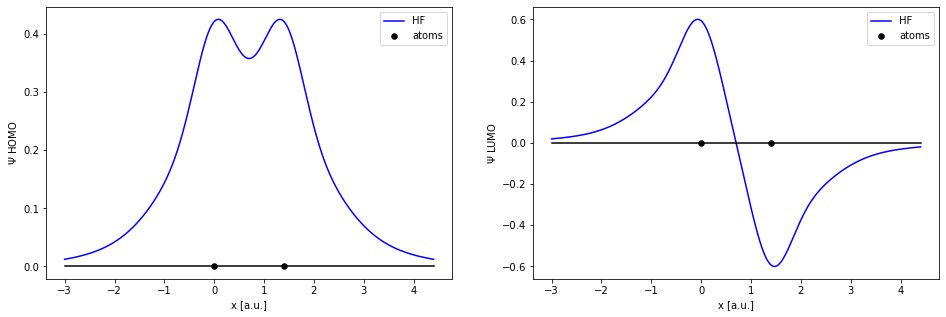

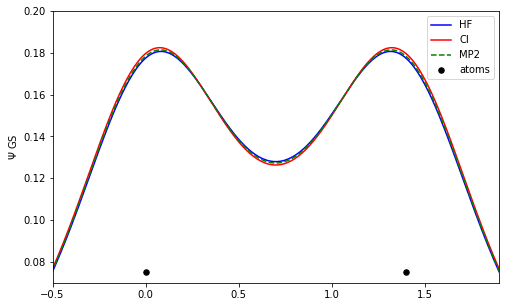

In [ ]:
### get eigenvalues and expansion coefficients of AO with HF
S, T, [V_A, V_B] = Overlap(), Kinetic(), Attraction() # obtain matrizes
H_core = T + V_A + V_B # calculate core Hamiltonian
eig, C = SCF(S, T + V_A + V_B, False) # perform SCF
### calculate values needed for further calculation
eps1, eps2 = min(eig), max(eig) # get orbital energies from eigenvalues
h11, h22, J11, J12, J22, K12 = 0.0, 0.0, 0.0, 0.0, 0.0, 0.0 # initialize matrix elements
for a in range(0,2):
    for b in range(0,2):
        h11 += C[a,0]*C[b,0]*H_core[a,b]
        h22 += C[a,1]*C[b,1]*H_core[a,b]
        for c in range(0,2):
            for d in range(0,2):
                J11 += C[a,0]*C[b,0]*C[c,0]*C[d,0]*Two(a,b,c,d)
                J12 += C[a,0]*C[b,0]*C[c,1]*C[d,1]*Two(a,b,c,d)
                J22 += C[a,1]*C[b,1]*C[c,1]*C[d,1]*Two(a,b,c,d)
                K12 += C[a,0]*C[b,1]*C[c,0]*C[d,1]*Two(a,b,c,d)
#### CI routine to obtain coefficients for CI wave function
CI = np.matrix([[2*h11 + J11, K12], [K12, 2*h22 + J22]]) # set up CI matrix
CI_eig, CI_vec = np.linalg.eigh(CI) # get eigenvalues of CI matrix
CI_vec = CI_vec/(abs(CI_vec[0,0])/CI_vec[0,0]) # adapt signs of coefficients for better visualization
### define function to calculate wave functions
def CGTO(r,R,atom): # function to calculate values of wave function for any given point
    value = CONTRACTION[atom,0]*(2*ALPHA[atom,0]/np.pi)**(3/4)*np.exp(-ALPHA[atom,0]*(r-R)**2)
    value += CONTRACTION[atom,1]*(2*ALPHA[atom,1]/np.pi)**(3/4)*np.exp(-ALPHA[atom,1]*(r-R)**2)
    value += CONTRACTION[atom,2]*(2*ALPHA[atom,2]/np.pi)**(3/4)*np.exp(-ALPHA[atom,2]*(r-R)**2)
    return value
### plot parameters
x_start, x_end, dx = -3, 3+RADIUS, 0.01
stepnum = int((x_end - x_start)/dx) + 1
### calculate values of wave functions
x, HOMO_HF, LUMO_HF = np.zeros(stepnum, float), np.zeros(stepnum, float), np.zeros(stepnum, float)
GS_D_HF = np.zeros(stepnum, float)
GS_D_CI = np.zeros(stepnum, float)
GS_D_MP2 = np.zeros(stepnum, float)
for i in range(0,stepnum): # fill arrays
    x[i] = x_start + i*dx
    # HF MO and ground state wave function
    HOMO_HF[i] = C[0,0]*CGTO(x[i], 0,0) + C[1,0]*CGTO(x[i], RADIUS,1)
    LUMO_HF[i] = C[0,1]*CGTO(x[i], 0,0) + C[1,1]*CGTO(x[i], RADIUS,1)
    GS_D_HF[i] = HOMO_HF[i]**2
    # CI ground state wave function
    GS_D_CI[i] = (CI_vec[0,0]**2*HOMO_HF[i]**2 + CI_vec[1,0]**2*LUMO_HF[i]**2)*(1/(CI_vec[0,0]**2+CI_vec[1,0]**2))
    # MP2 ground state wave function (To 1st-order)
    GS_D_MP2[i] = (HOMO_HF[i]**2 + (K12/(2*(eps1 - eps2)))**2*LUMO_HF[i]**2)*(1/(1+(K12/(2*(eps1 - eps2)))**2))
### create plot
fig, ((ax1,ax2)) = plt.subplots(1, 2, figsize=(16,5)) # initialize plot
# plot HOMO wave functions
ax1.plot(x, HOMO_HF, 'b', label='HF')
ax1.plot(x, np.zeros(stepnum, float), 'k') # show x axis
ax1.scatter(0, 0, 30, 'k', label='atoms') # show left atom
ax1.scatter(RADIUS, 0, 30, 'k') # show right atom
# plot LUMO wave functions
ax2.plot(x, LUMO_HF, 'b', label='HF')
ax2.plot(x, np.zeros(stepnum, float), 'k') # show x axis
ax2.scatter(0, 0.0, 30, 'k', label='atoms') # show left atom
ax2.scatter(RADIUS, 0.0, 30, 'k') # show right atom
# show legend in all subplots
ax1.legend(); ax2.legend()#; ax3.legend(); ax4.legend()
# set axis labels
ax1.set_ylabel(r"$\Psi$ HOMO"); ax1.set_xlabel('x [a.u.]')
ax2.set_ylabel(r"$\Psi$ LUMO"); ax2.set_xlabel('x [a.u.]')
# show plot
plt.show()
# plot for Ground state probability
fig, ax = plt.subplots(figsize=(8,5)) # initialize plot
ax.plot(x, GS_D_HF, 'b', label='HF')
ax.plot(x, GS_D_CI, 'r', label='CI')
ax.plot(x, GS_D_MP2, 'g--', label='MP2')
ax.plot(x, np.zeros(stepnum, float), 'k') # show x axis
ax.scatter(0, 0.075, 30, 'k', label='atoms') # show left atom
ax.scatter(RADIUS, 0.075, 30, 'k') # show right atom
#ax.set_xlim([-0.2, 0.4])
ax.set_xlim([-0.5, 1.9])
#ax.set_ylim([0.14, 0.19])
ax.set_ylim([0.07, 0.2])
ax.legend()
ax.set_ylabel(r"$\Psi$ GS"); ax1.set_xlabel('x [a.u.]')
plt.show()


# Dissociation curve

Modifying the former constant 'RADIUS' gives the option to plot the dissociation curve. To speed up the calculation the analytical solution of the Hartree-Fock coefficient matrix
\begin{equation}
C = \left( \begin{array}{rr} (2(1+S_{12}))^{-1/2} & (2(1-S_{12}))^{-1/2} \\(2(1+S_{12}))^{-1/2} & -(2(1-S_{12}))^{-1/2} \\ \end{array}\right)
\end{equation}
for hydrogen can be used instead of the SCF procedure. This also avoids numerical difficulties with the HF implementation for larger bond lengths. Please note that the unrestricted Hartree-Fock method (UHF) is used!

To better understand the dissociation curve a plot showing the change of the wave function with increasing bond length is created afterwards.

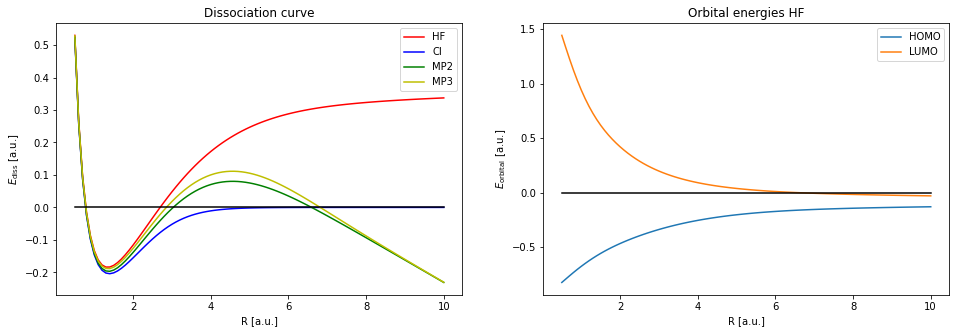

In [ ]:
### initialize variables needed for all plots
x, E_HF, E_CI, E_MP2, E_MP3 = [], [], [], [], [] # lists for total energies
HOMO_HF, LUMO_HF = [], [] # lists for orbital energies
### plot parameters
RADIUS_MIN, RADIUS_MAX = 50, 1001 # scan range RADIUS, Å times factor 100
RADIUS_STEP = 10 # step size scan RADIUS, Å times factor 100
### loop over different RADIUS values
for RADIUS in range(RADIUS_MIN, RADIUS_MAX, RADIUS_STEP): # loop to change RADIUS
    RADIUS = RADIUS / 100 # obtain new RADIUS
    ### get needed values for energies
    # obtain coefficient matrix from analytical solution
    S, T, [V_A, V_B] = Overlap(), Kinetic(), Attraction() # obtain matrizes
    H_core = T + V_A + V_B # calculate core Hamiltonian
    eig, C = SCF(S, T + V_A + V_B, False) # perform SCF
    #C = np.matrix([[(2*(1+S[0,1]))**(-0.5), (2*(1-S[0,1]))**(-0.5)], [(2*(1+S[0,1]))**(-0.5), -(2*(1-S[0,1]))**(-0.5)]])
    # get matrix elements
    h11, h22, J11, J12, J22, K12 = 0.0, 0.0, 0.0, 0.0, 0.0, 0.0 # initialize matrix elements
    for a in range(0,2):
        for b in range(0,2):
            h11 += C[a,0]*C[b,0]*H_core[a,b]
            h22 += C[a,1]*C[b,1]*H_core[a,b]
            for c in range(0,2):
                for d in range(0,2):
                    J11 += C[a,0]*C[b,0]*C[c,0]*C[d,0]*Two(a,b,c,d)
                    J12 += C[a,0]*C[b,0]*C[c,1]*C[d,1]*Two(a,b,c,d)
                    J22 += C[a,1]*C[b,1]*C[c,1]*C[d,1]*Two(a,b,c,d)
                    K12 += C[a,0]*C[b,1]*C[c,0]*C[d,1]*Two(a,b,c,d)
    eps1, eps2 = h11 + J11, h22 + 2*J12 - K12 # orbital energies
    ### get energies of all methods, add to their list
    x.append(RADIUS)
    E_0 = 2*h11 + J11 # HF ground state energy
    E_HF.append(E_0 + CHARGE[0]*CHARGE[1]/RADIUS - E_ATOMS[0] - E_ATOMS[1]) # HF
    CI = np.matrix([[2*h11 + J11, K12], [K12, 2*h22 + J22]]) # set up CI matrix
    CI_eig, CI_vec = np.linalg.eigh(CI) # get eigenvalues of CI matrix
    E_CI.append(min(CI_eig) + CHARGE[0]*CHARGE[1]/RADIUS - E_ATOMS[0] - E_ATOMS[1]) # CI
    E_MP2.append(E_0 + K12**2 / (2*(eps1 - eps2)) + CHARGE[0]*CHARGE[1]/RADIUS - E_ATOMS[0] - E_ATOMS[1])
    E_MP3.append(E_0 + (K12**2*(J11 + J22 - 4*J12 + 2*K12)) / (4*(eps1 - eps2)**2) + CHARGE[0]*CHARGE[1]/RADIUS - E_ATOMS[0] - E_ATOMS[1])
    HOMO_HF.append(eps1)
    LUMO_HF.append(eps2)

fig, ((ax1),(ax2)) = plt.subplots(1, 2, figsize=(16,5)) # initialize plot
# plot dissociation curves
ax1.set_title('Dissociation curve') # initialize figure
ax1.plot(x, E_HF, 'r', label='HF') # plot HF
ax1.plot(x, E_CI, 'b', label='CI') # plot CI
ax1.plot(x, E_MP2, 'g', label='MP2') # plot MP2
ax1.plot(x, E_MP3, 'y', label='MP3') # plot MP3
ax1.plot(x, np.zeros(len(x), float), 'k') # show x axis
ax1.set_xlabel('R [a.u.]') # label x axis
ax1.set_ylabel(r"$E_\mathrm{diss}$" + ' [a.u.]') # label y axis
ax1.legend() # show legend
# plot orbital energies of HF
ax2.set_title('Orbital energies HF')
ax2.plot(x, HOMO_HF, label='HOMO')
ax2.plot(x, LUMO_HF, label='LUMO')
ax2.plot(x, np.zeros(len(x), float), 'k') # show x axis
ax2.set_xlabel('R [a.u.]') # label x axis
ax2.set_ylabel(r"$E_\mathrm{orbital}$" + ' [a.u.]') # label y axis
ax2.legend() # show legend
# show plot
plt.show() # show plot

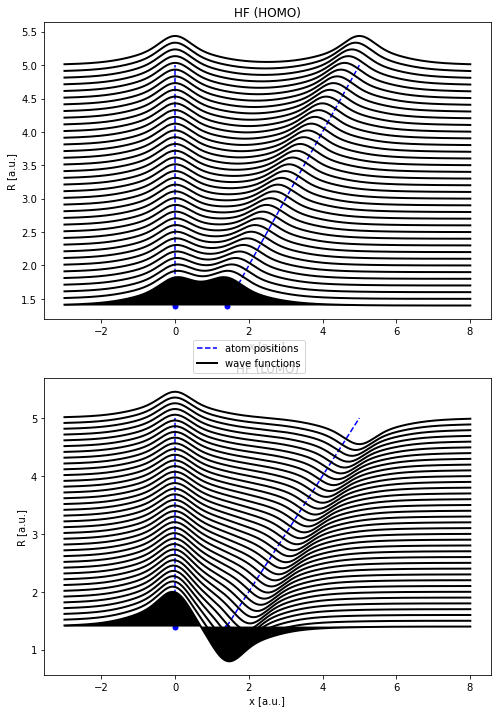

In [ ]:
### initialize variables needed for all plots
r, x_array, HOMO_HF, LUMO_HF = [], [], [], []
HOMO_CI, LUMO_CI = [], []
### plot parameters
RADIUS_MIN, RADIUS_MAX = 140, 501 # scan range RADIUS, Å times factor 100
RADIUS_STEP = 10 # step size scan RADIUS, Å times factor 100
### define function to calculate wave functions
def CGTO(r,R,atom): # function to calculate values of wave function for any given point
    value = CONTRACTION[atom,0]*(2*ALPHA[atom,0]/np.pi)**(3/4)*np.exp(-ALPHA[atom,0]*(r-R)**2)
    value += CONTRACTION[atom,1]*(2*ALPHA[atom,1]/np.pi)**(3/4)*np.exp(-ALPHA[atom,1]*(r-R)**2)
    value += CONTRACTION[atom,2]*(2*ALPHA[atom,2]/np.pi)**(3/4)*np.exp(-ALPHA[atom,2]*(r-R)**2)
    return value
### loop over different RADIUS values
for RADIUS in range(RADIUS_MIN, RADIUS_MAX, RADIUS_STEP): # loop to change RADIUS
    RADIUS = RADIUS / 100 # obtain new RADIUS
    r.append(RADIUS)
    ### get needed values for energies
    # obtain coefficient matrix from analytical solution
    S, T, [V_A, V_B] = Overlap(), Kinetic(), Attraction() # obtain matrizes
    H_core = T + V_A + V_B # calculate core Hamiltonian
    eig, C = SCF(S, T + V_A + V_B, False) # perform SCF
    #C = np.matrix([[(2*(1+S[0,1]))**(-0.5), (2*(1-S[0,1]))**(-0.5)], [(2*(1+S[0,1]))**(-0.5), -(2*(1-S[0,1]))**(-0.5)]])
    # get matrix elements
    h11, h22, J11, J12, J22, K12 = 0.0, 0.0, 0.0, 0.0, 0.0, 0.0 # initialize matrix elements
    for a in range(0,2):
        for b in range(0,2):
            h11 += C[a,0]*C[b,0]*H_core[a,b]
            h22 += C[a,1]*C[b,1]*H_core[a,b]
            for c in range(0,2):
                for d in range(0,2):
                    J11 += C[a,0]*C[b,0]*C[c,0]*C[d,0]*Two(a,b,c,d)
                    J12 += C[a,0]*C[b,0]*C[c,1]*C[d,1]*Two(a,b,c,d)
                    J22 += C[a,1]*C[b,1]*C[c,1]*C[d,1]*Two(a,b,c,d)
                    K12 += C[a,0]*C[b,1]*C[c,0]*C[d,1]*Two(a,b,c,d)
    eps1, eps2 = h11 + J11, h22 + 2*J12 - K12 # orbital energies
    ### perform CI
    CI = np.matrix([[2*h11 + J11, K12], [K12, 2*h22 + J22]]) # set up CI matrix
    CI_eig, CI_vec = np.linalg.eigh(CI) # get eigenvalues of CI matrix
    CI_vec = CI_vec/(abs(CI_vec[0,0])/CI_vec[0,0]) # adapt signs of coefficients for better visualization
    ### calculate wave functions with CI and HF
    # plot parameters
    x_start, x_end, dx = -3, 3+RADIUS_MAX/100, 0.01
    stepnum = int((x_end - x_start)/dx) + 1
    # create local list for wave functions
    WF_x = np.zeros(stepnum, float)
    WF_HOMO_HF, WF_LUMO_HF = np.zeros(stepnum, float), np.zeros(stepnum, float)
    for i in range(0,stepnum): # fill arrays
        # get x values
        WF_x[i] = x_start + i*dx
        # HF wave function
        WF_HOMO_HF[i] = C[0,0]*CGTO(WF_x[i], 0,0) + C[1,0]*CGTO(WF_x[i], RADIUS,1)
        WF_LUMO_HF[i] = C[0,1]*CGTO(WF_x[i], 0,0) + C[1,1]*CGTO(WF_x[i], RADIUS,1)
    # add to global list of wave functions
    x_array.append(WF_x)
    HOMO_HF.append(WF_HOMO_HF); LUMO_HF.append(WF_LUMO_HF)

### create plot showing change of wave functions for increasing bond length
fig, ax = plt.subplots(2, 1, figsize=(8,12)) # initialize plot
# put data into plot
ax[0].plot(np.zeros(len(r), float), r, 'b--', zorder=0, label='atom positions') # show position of atom 1
ax[1].plot(np.zeros(len(r), float), r, 'b--', zorder=0, label='atom positions') # show position of atom 1
ax[0].plot(r, r, 'b--', zorder=0),
ax[1].plot(r, r, 'b--', zorder=0),
for i in range(1,len(x_array)): # do for all studied bond lengths
    ax[0].plot(x_array[i], HOMO_HF[i]+r[i], 'k', lw=2, zorder=(i+1)**2) # show HOMO HF
    ax[1].plot(x_array[i], LUMO_HF[i]+r[i], 'k', lw=2, zorder=(i+1)**2) # show LUMO HF
ax[0].plot(x_array[0], HOMO_HF[0]+r[0], 'k', lw=2, zorder=1, label='wave functions') # show HOMO HF for lowest RADIUS
ax[1].plot(x_array[0], LUMO_HF[0]+r[0], 'k', lw=2, zorder=1, label='wave functions') # show LUMO HF for lowest RADIUS
ax[0].fill_between(x_array[0], HOMO_HF[0]+r[0], r[0], facecolor='k', lw=0, zorder=1) # black HOMO HF for lowest RADIUS
ax[1].fill_between(x_array[0], LUMO_HF[0]+r[0], r[0], facecolor='k', lw=0, zorder=1) # black LUMO HF for lowest RADIUS

ax[0].plot(0, RADIUS_MIN/100, 'b.', ms=10, zorder=0) # show atom 1
ax[0].plot(RADIUS_MIN/100, RADIUS_MIN/100, 'b.', ms=10, zorder=0) # show atom 2
ax[1].plot(0, RADIUS_MIN/100, 'b.', ms=10, zorder=0) # show atom 1
ax[1].plot(RADIUS_MIN/100, RADIUS_MIN/100, 'b.', ms=10, zorder=0) # show atom 2

# set up everything else
ax[0].set_xlabel('x [a.u.]')
ax[0].set_ylabel('R [a.u.]')
ax[1].set_xlabel('x [a.u.]')
ax[1].set_ylabel('R [a.u.]')
handles, labels = ax[0].get_legend_handles_labels() # prepare to show legend
fig.legend(handles, labels, loc='center') # show global legend
ax[0].set_title('HF (HOMO)')
ax[1].set_title('HF (LUMO)')
plt.show()